In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("data/day.csv")

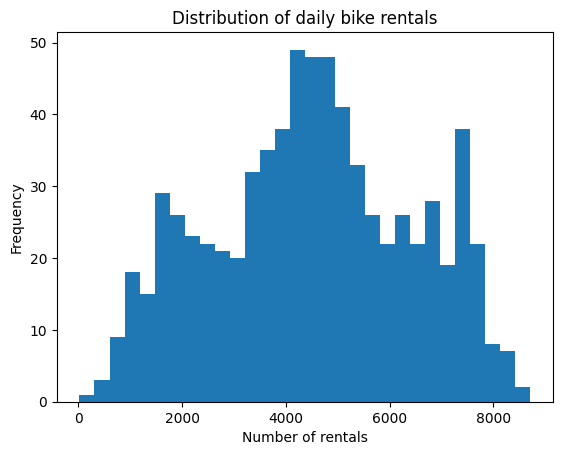

In [3]:
# show distribuition of cnt - target variable
plt.hist(df["cnt"], bins = 30)
plt.xlabel("Number of rentals")
plt.ylabel("Frequency")
plt.title("Distribution of daily bike rentals")
plt.show()

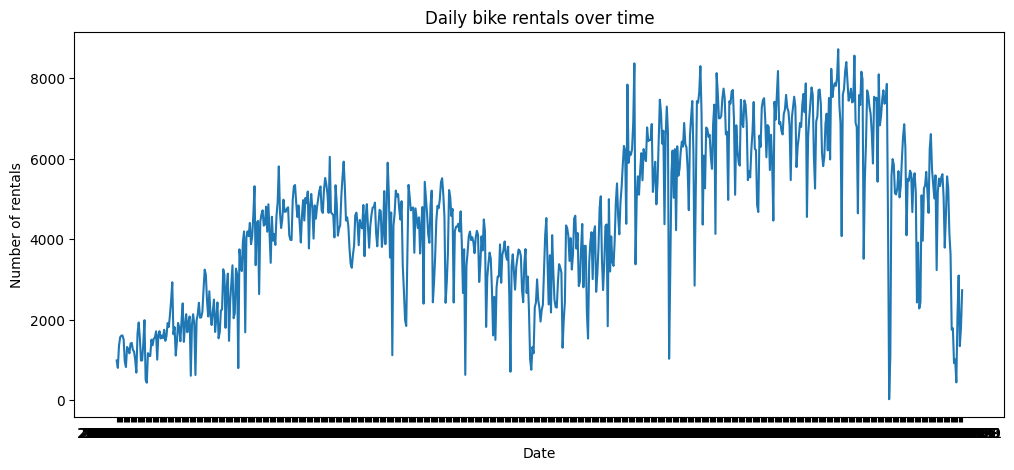

In [12]:
plt.figure(figsize=(12,5))
plt.plot(df['dteday'], df['cnt'])
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.title("Daily bike rentals over time")
plt.show()

In [8]:
df.groupby('season')['cnt'].mean()

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64

In [9]:
df.groupby('weathersit')['cnt'].mean()

weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64

In [10]:
df.groupby('workingday')['cnt'].mean()

workingday
0    4330.168831
1    4584.820000
Name: cnt, dtype: float64

In [14]:
for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(f"\n{col}")
    print(df.groupby(col)["cnt"].agg(["mean", "median", "count"]))


season
               mean  median  count
season                            
1       2604.132597  2209.0    181
2       4992.331522  4941.5    184
3       5644.303191  5353.5    188
4       4728.162921  4634.5    178

yr
           mean  median  count
yr                            
0   3405.761644  3740.0    365
1   5599.934426  5927.0    366

mnth
             mean  median  count
mnth                            
1     2176.338710  1939.0     62
2     2655.298246  2402.0     57
3     3692.258065  3216.5     62
4     4484.900000  4293.5     60
5     5349.774194  4890.5     62
6     5772.366667  5308.5     60
7     5563.677419  5446.5     62
8     5664.419355  5229.5     62
9     5766.516667  5384.0     60
10    5199.225806  5013.0     62
11    4247.183333  4081.0     60
12    3403.806452  3444.0     62

holiday
                mean  median  count
holiday                            
0        4527.104225  4558.0    710
1        3735.000000  3351.0     21

weekday
                mean  me

In [18]:
df[["temp", "atemp", "hum", "windspeed", "cnt"]].corr()["cnt"].sort_values()

windspeed   -0.234545
hum         -0.100659
temp         0.627494
atemp        0.631066
cnt          1.000000
Name: cnt, dtype: float64

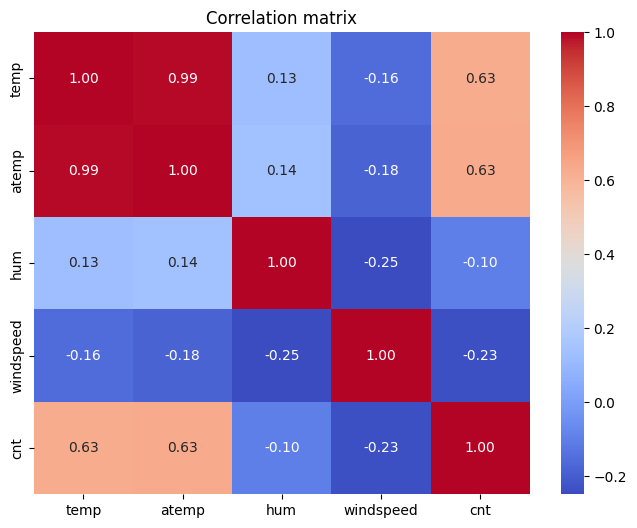

In [20]:
import seaborn as sns
corr = df[["temp", "atemp", "hum", "windspeed", "cnt"]].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt="0.2f")
plt.title("Correlation matrix")
plt.show()

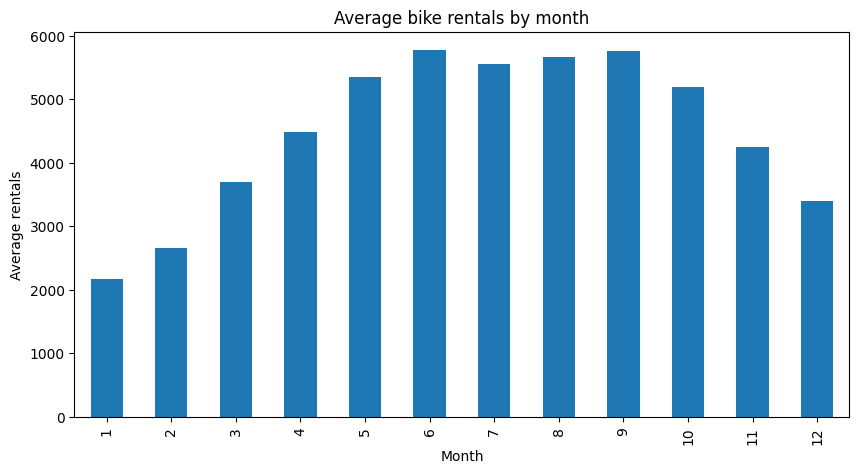

In [21]:
monthly = df.groupby("mnth")["cnt"].mean()
monthly.plot(kind="bar", figsize=(10,5))
plt.xlabel("Month")
plt.ylabel("Average rentals")
plt.title("Average bike rentals by month")
plt.show()

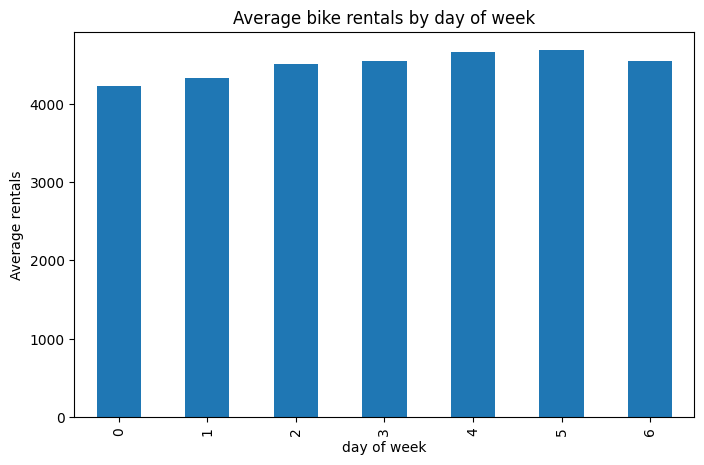

In [22]:
daily = df.groupby("weekday")["cnt"].mean()
daily.plot(kind="bar", figsize=(8,5))
plt.xlabel("day of week")
plt.ylabel("Average rentals")
plt.title("Average bike rentals by day of week")
plt.show()

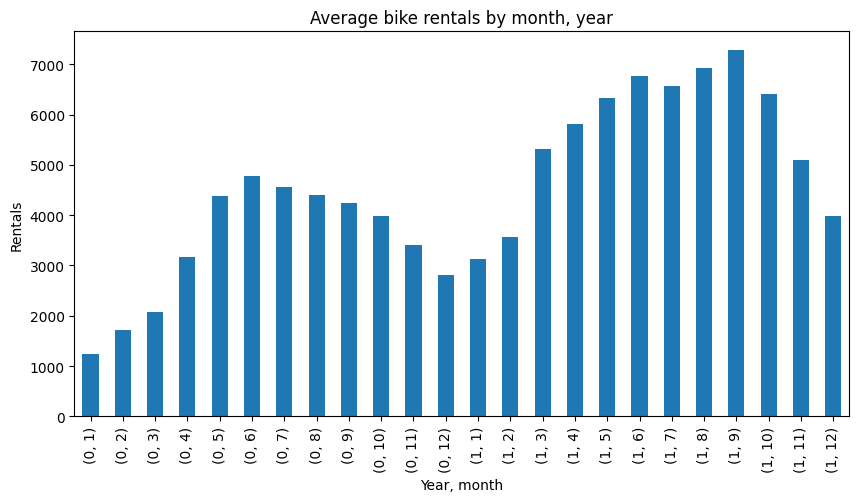

In [24]:
usage = df.groupby(['yr', 'mnth'])['cnt'].mean()
usage.plot(kind="bar", figsize=(10,5))
plt.xlabel("Year, month")
plt.ylabel("Rentals")
plt.title("Average bike rentals by month, year")
plt.show()

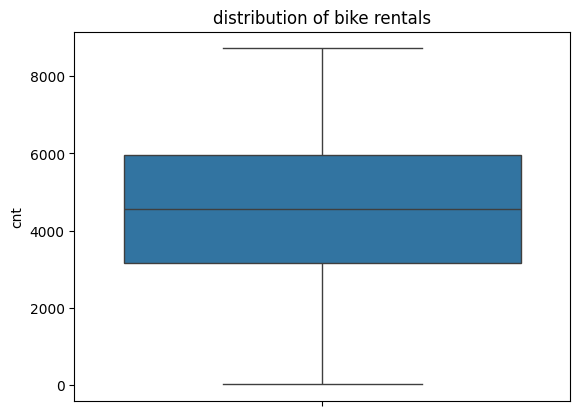

In [25]:
sns.boxplot(y=df["cnt"])
plt.title("distribution of bike rentals")
plt.show()